In [1]:
import math
import numpy as np
import matplotlib
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [20]:
class Value:

    def __init__(self, data):
        self.data = data
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data)
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data)
        return out

a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)

In [14]:
a+b
#a.__add__(b)

Value(data=-1.0)

In [21]:
a*b + c

Value(data=4.0)

In [13]:
# What is init, repr?
# Self, other are special words?
# Methods are too?

In [31]:
# We also want some notion of children, and the operation that got us there

In [49]:
class Value:

    def __init__(self, data, _children = (), _op =''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
d = a*b + c

In [50]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [51]:
d._op

'+'

In [52]:
d

Value(data=4.0)

In [53]:
# Lets visualise this

In [54]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label= "{ data %.4f }" % (n.data, ), shape="record")
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid+n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

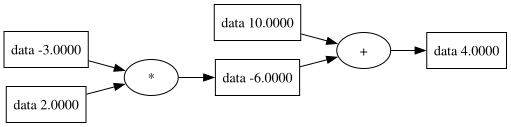

In [56]:
draw_dot(d)

In [42]:
# can add labels
class Value:

    def __init__(self, data, _children = (), _op ='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
d = a*b + c
d.label='d'

In [43]:
# If I had graphviz, do it again

In [44]:
# Lets maintain derivatives of output wrt something

In [58]:
# can add labels
class Value:

    def __init__(self, data, _children = (), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b
e.label='e'
d = e + c
d.label='d'
f = Value(-2.0, label='f')
L = d*f
L.label='L'
L

Value(data=-8.0)

In [57]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label= "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape="record")
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid+n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

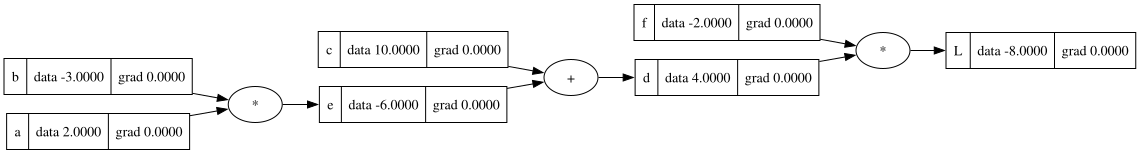

In [60]:
draw_dot(L)

In [62]:
# Moving into manual backpropagation
# dL/dL = 1

def numerical_test():
    h = 0.0001
    
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b
    e.label='e'
    d = e + c
    d.label='d'
    f = Value(-2.0, label='f')
    L = d*f
    L.label='L'
    L1 = L.data
    
    a = Value(2.0+h, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b
    e.label='e'
    d = e + c
    d.label='d'
    f = Value(-2.0, label='f')
    L = d*f
    L.label='L'
    L2 = L.data

    print((L2-L1)/h)

#dL/da - can do this for everything
numerical_test()

6.000000000021544


In [65]:
# dL/dd
# L = d * f, dL/dd = f
# dL/df = d
# dL/dc = dd/dc * f + df/dc * c = dd/dc * f = d(c+e)/dc * f = f
# dL/de = f
# dL/db = dL/de * de/db = f * a = -4
# dL/da = dL/de * de/da = f * b = 6
L.grad=1.0
d.grad=-2.0
f.grad=4.0
c.grad=-2
e.grad=-2
b.grad=-4
a.grad=6

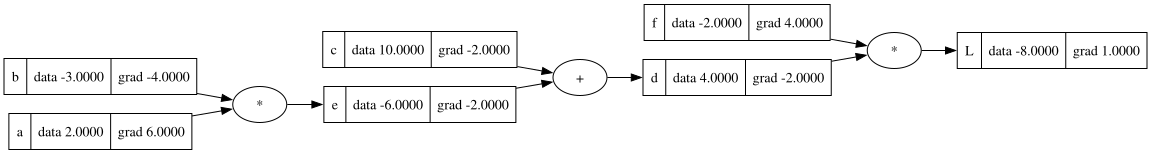

In [66]:
draw_dot(L)

In [68]:
# Plus node routes gradient through
# Chain through the output of some node
# dL/dchild = dL/dparent * dparent/dchild

In [69]:
# We could now do gradient descent with the gradients we have

In [70]:
# Neuron generally:
# Has a bunch of xi that come in
# Synapse interact to get wixi
# The neuron has an inherent bias - sum(wixi) + b
# Apply activation function (like tanh)
# output f(sum(wixi) + b)

In [80]:
# this fails if I just use (self) for children instead of (self, ) - why?
class Value:

    def __init__(self, data, _children = (), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self, ), _op='tanh')
        return out

In [89]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

# activation
o = n.tanh(); o.label = 'o'

In [86]:
# This is basically what happens in a neuron

In [91]:
# For back prop, I want do/dwi

In [92]:
o.grad = 1.0


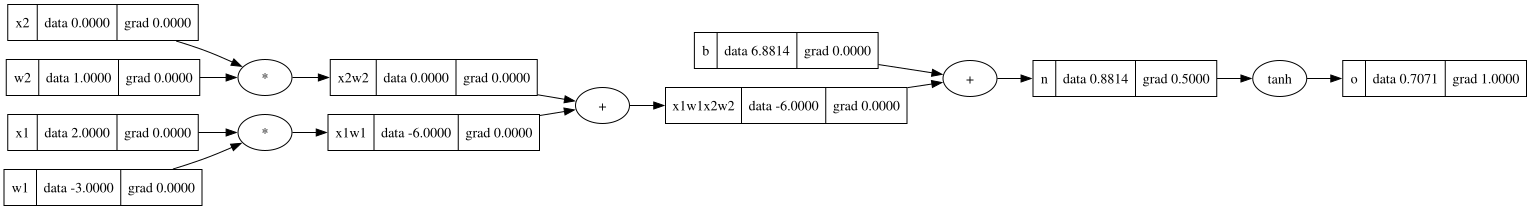

In [96]:
draw_dot(o)

In [94]:
#do/dn = 1 - o^2, as o = tanh(n)
n.grad=1 - o.data ** 2

In [97]:
#do/db = do/dn * dn/db = 0.5
# By + sign flow, we get:
b.grad = 0.5
x1w1x2w2.grad = 0.5
# again
x2w2.grad = 0.5
x1w1.grad = 0.5

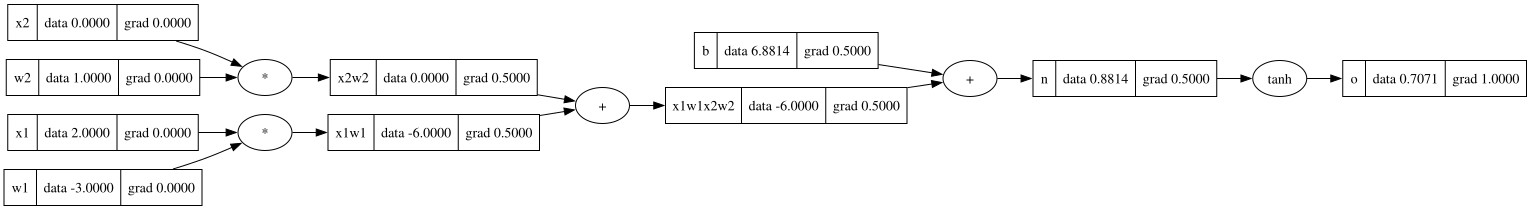

In [98]:
draw_dot(o)

In [100]:
# Now we need to finish off
#do/dx2 = do/dx2w2 * dx2w2 = 0.5 * w2 = 0.5
#do/dw2 = 0
#do/dx1 = 0.5 * -3 = -1.5
#do/dw1 = 1.0
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

In [101]:
# Now we'll automate

In [102]:
class Value:

    def __init__(self, data, _children = (), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad = out.grad * 1.0
            other.grad = out.grad * 1.0
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad = out.grad * other.data
            other.grad = out.grad * self.data
        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self, ), _op='tanh')
        def _backward():
            self.grad = (1 - t ** 2) * out.grad
        out._backward = _backward
        
        return out

In [103]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

# activation
o = n.tanh(); o.label = 'o'

In [107]:
# First, manually call all backwards in the right layer order
o.grad = 1.0
o._backward()
n._backward()
b._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()
x1._backward()
w1._backward()
x2._backward()
w2._backward()

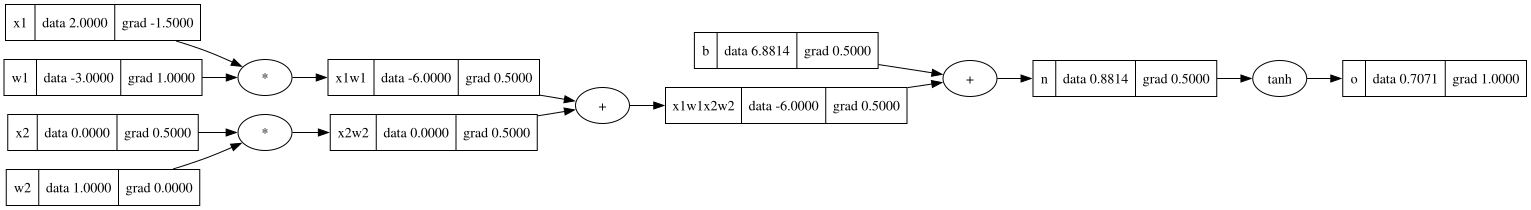

In [108]:
draw_dot(o)

In [149]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

# activation
o = n.tanh(); o.label = 'o'; o.grad = 1.0

In [150]:
# Now we could automate this by recursively calling on children, or performing topological sort on graph once
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.881373587019543),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [151]:
for node in reversed(topo):
    print(node)
    node._backward()

Value(data=0.7071067811865476)
Value(data=0.8813735870195432)
Value(data=-6.0)
Value(data=0.0)
Value(data=0.0)
Value(data=1.0)
Value(data=-6.0)
Value(data=2.0)
Value(data=-3.0)
Value(data=6.881373587019543)


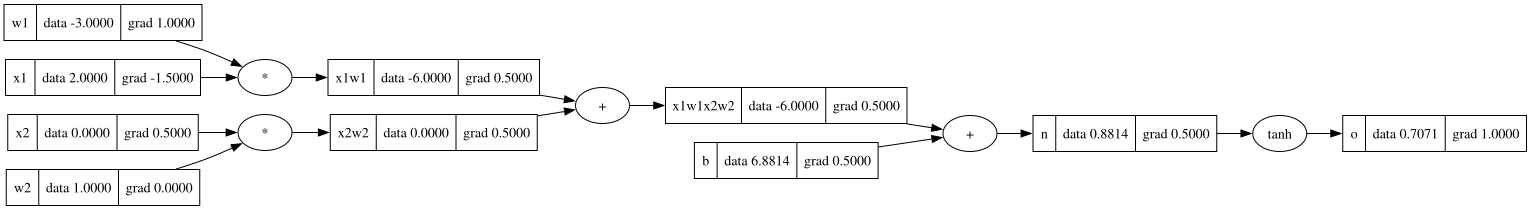

In [152]:
draw_dot(o)

In [157]:
# move in backward
class Value:

    def __init__(self, data, _children = (), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad = out.grad * 1.0
            other.grad = out.grad * 1.0
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad = out.grad * other.data
            other.grad = out.grad * self.data
        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self, ), _op='tanh')
        def _backward():
            self.grad = (1 - t ** 2) * out.grad
        out._backward = _backward

        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(o)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
        

In [158]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

# activation
o = n.tanh(); o.label = 'o'; o.grad = 1.0

In [159]:
o.backward()

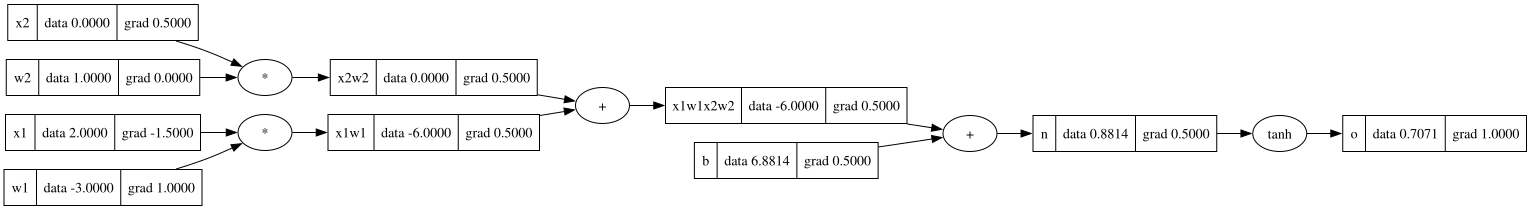

In [160]:
draw_dot(o)

In [172]:
# fix bug where we use inputs more than once - we must sum over children
class Value:

    def __init__(self, data, _children = (), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self, ), _op='tanh')
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward

        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
        

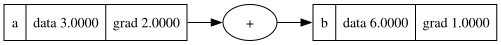

In [173]:
a = Value(3.0, label='a')
b = a + a; b.label='b'
b.backward()
draw_dot(b)

In [174]:
# This is just multivariate chain rule!!

In [175]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

# activation
o = n.tanh(); o.label = 'o'; o.grad = 1.0

In [ ]:
# Exercise - lets force full atomisation of exp

In [194]:
# fix bug where we use inputs more than once - we must sum over children
# add rmul, radd, div, exp
class Value:

    def __init__(self, data, _children = (), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # Allow constant operations
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward
        return out

    def __mul__(self, other):
        # Allow constant operations
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        # This is saying if we know out.grad, how does the gradient propagate backwards to children
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out

    def __truediv__(self, other):
        return self * (other ** -1)

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __rmul__(self, other):
        # allows 2 * a, as well as a * 2
        return self * other

    def __radd__(self, other):
        # allows 2 + a, as well as a + 2
        return self + other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers"
        out = Value(self.data ** other, (self, ), f'**{other}')
        def _backward():
            low_pow = self.data ** (other - 1)
            self.grad += (other * low_pow) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self, ), _op='tanh')
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), _op='exp') 
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out
        
    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
        

In [200]:
# This is with hardcode
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

# activation
o = n.tanh(); o.label = 'o'; o.grad = 1.0

In [198]:
o.backward()

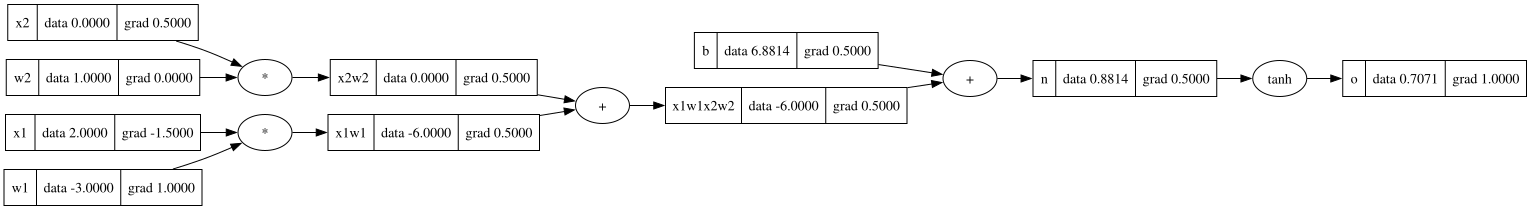

In [199]:
draw_dot(o)

In [201]:
# This is with hardcode
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

# activation
e = (2*n).exp()
o = (e-1) / (e+1); o.label = 'o'; o.grad = 1.0

In [202]:
o.backward()

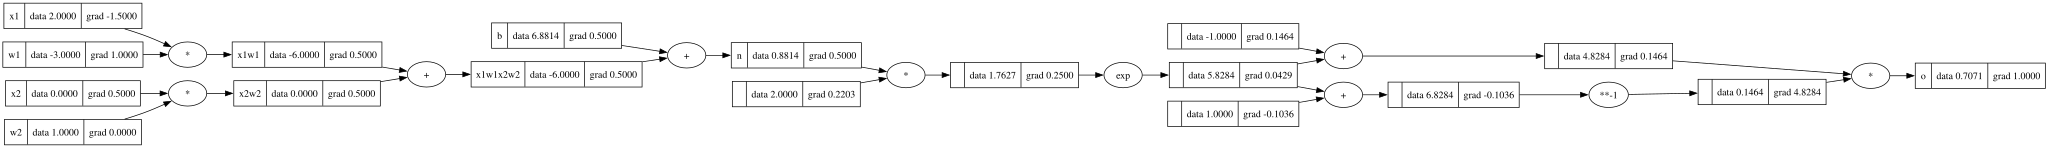

In [203]:
draw_dot(o)